# **Fitur Unik 2: Penjelasan Prediksi dengan Integrated Gradients**

Model final memberi satu angka probabilitas risiko diabetes. Untuk aplikasi kesehatan, angka saja tidak cukup. Pengguna perlu tahu **faktor apa yang membuat risikonya tinggi atau rendah**, dan tim pengembang perlu memastikan model mengambil keputusan berdasarkan pola yang masuk akal secara medis, bukan pola yang kebetulan.

Fitur unik kedua menjawab kebutuhan ini dengan **Integrated Gradients** (IG), metode atribusi untuk jaringan saraf dari Sundararajan dkk. (2017). IG menghitung kontribusi setiap fitur terhadap selisih probabilitas antara responden yang dijelaskan dan sebuah **baseline**. IG ditulis sendiri dengan `tf.GradientTape` di `src/inference.py`, jadi aplikasi memakai kode yang sama persis.

Supaya fitur ini tidak sekadar tampilan, dampaknya dibuktikan lewat empat pengujian di data validation:

| Pengujian | Pertanyaan yang dijawab |
|---|---|
| Completeness | Apakah jumlah kontribusi sama dengan selisih probabilitas |
| Deletion test | Apakah fitur yang ditunjuk IG benar-benar yang paling menggerakkan prediksi |
| Sensitivitas baseline | Apakah kesimpulan berubah kalau baseline diganti |
| Kesesuaian domain | Apakah arah pengaruh fitur sesuai dengan faktor risiko diabetes yang dikenal |

Model yang dijelaskan adalah model final (`models/mlp_final.keras`). Data test tetap tidak disentuh.

**Penanggung jawab:** Erik Hamli (231110980)

## **1. Import Library dan Konfigurasi**

Notebook ini tidak melatih model, jadi tidak ada saklar `RUN_EXPERIMENTS`. Seluruh perhitungan selesai dalam beberapa menit.

In [2]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.stats import spearmanr

from src import config
from src import preprocessing as prep
from src import evaluation as ev
from src import inference as inf
from src import visualization as viz

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
viz.set_style()
WARNA_NAIK, WARNA_TURUN, WARNA_UTAMA = "#eb6834", "#2a78d6", "#2a78d6"
rng = np.random.default_rng(config.SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## **2. Memuat Data dan Model Final**

Probabilitas model final di data validation dibandingkan dengan probabilitas yang tersimpan di notebook 05, untuk memastikan model yang dijelaskan adalah model yang sama.

In [3]:
data = prep.prepare_datasets()
assert data["test_fingerprint"] == prep.load_preprocessing_config()["split"]["test_fingerprint"]
model_cfg = json.loads((config.MODELS_DIR / "model_config.json").read_text(encoding="utf-8"))
model = keras.models.load_model(ROOT / model_cfg["model_path"], compile=False)
THRESHOLD = model_cfg["threshold"]

X_val, y_val = data["X_val"], data["y_val"].astype(int)
X_val_raw = data["X_val_raw"].reset_index(drop=True)
prob_val = inf.predict_proba(model, X_val)
prob_05 = np.load(config.RESULTS_DIR / "05_prob_validation_seed42.npz")["final"]

print(f"Model      : {model_cfg['model_path']} | loss {model_cfg['loss']} | threshold {THRESHOLD}")
print(f"Validation : {X_val.shape}")
print("Probabilitas sama dengan notebook 05:", np.allclose(prob_val, prob_05, atol=1e-6))

Model      : models/mlp_final.keras | loss BCE | threshold 0.13
Validation : (34332, 21)
Probabilitas sama dengan notebook 05: True


## **3. Menentukan Baseline**

IG selalu menjelaskan prediksi **relatif terhadap baseline**, jadi pemilihan baseline menentukan cara membaca hasilnya. Baseline yang dipakai adalah **rata-rata data train di ruang fitur yang sudah di-scaling**. Untuk fitur numerik dan ordinal, nilainya 0 (karena sudah distandardisasi). Untuk fitur biner, nilainya sama dengan proporsi "ya" di data train, misalnya 0,43 untuk `HighBP`.

Dengan baseline ini, kontribusi dibaca sebagai: **"dibanding responden rata-rata, fitur ini menaikkan atau menurunkan probabilitas diabetes sebesar sekian poin"**. Alternatif lain seperti vektor nol tidak punya makna yang jelas di data ini, karena nol untuk fitur biner berarti "tidak" pada semua pertanyaan, sedangkan nol untuk fitur ter-scaling berarti nilai rata-rata. Campuran keduanya bukan profil responden yang masuk akal (Sturmfels dkk., 2020).

In [4]:
baseline = data["X_train"].mean(axis=0).astype(np.float32)
baseline_prob = float(inf.predict_proba(model, baseline[None, :])[0])
baseline_raw = data["X_train_raw"].mean()

tabel_baseline = pd.DataFrame({
    "nama": [config.FEATURE_INFO[c]["nama"] for c in config.FEATURE_COLS],
    "rata-rata (nilai asli)": baseline_raw[config.FEATURE_COLS].values,
    "baseline (ter-scaling)": baseline,
}, index=config.FEATURE_COLS)
display(tabel_baseline.round(3))
print(f"Probabilitas diabetes untuk baseline : {baseline_prob:.4f}")
print(f"Proporsi diabetes di data train      : {data['y_train'].mean():.4f}")

,nama,rata-rata (nilai asli),baseline (ter-scaling)
HighBP,Tekanan darah tinggi,0.454,0.454
HighChol,Kolesterol tinggi,0.441,0.441
CholCheck,Cek kolesterol,0.959,0.959
BMI,Indeks massa tubuh,28.557,0.000
Smoker,Pernah merokok,0.465,0.465
Stroke,Riwayat stroke,0.045,0.045
HeartDiseaseorAttack,Penyakit jantung,0.104,0.104
PhysActivity,Aktivitas fisik,0.733,0.733
Fruits,Konsumsi buah,0.613,0.613
Veggies,Konsumsi sayur,0.794,0.794


Probabilitas diabetes untuk baseline : 0.1175
Proporsi diabetes di data train      : 0.1530


**Interpretasi:** Baseline berisi nilai rata-rata seluruh fitur di data train. Fitur numerik dan ordinal bernilai 0 setelah scaling, dengan nilai aslinya misalnya BMI 28,56, GenHlth 2,60, dan kelompok usia 8,09 (sekitar 55 sampai 59 tahun). Fitur biner bernilai sesuai proporsinya, misalnya `HighBP` 0,454 dan `CholCheck` 0,959.

Probabilitas diabetes untuk baseline adalah **0,1175**, lebih rendah dari proporsi diabetes di data train (0,1530). Selisih ini wajar karena model bersifat nonlinear. Probabilitas untuk "profil rata-rata" tidak sama dengan rata-rata probabilitas seluruh responden, yang di data validation sebesar 0,1397. Karena itu kontribusi IG dibaca sebagai **"dibanding profil responden rata-rata dengan risiko sekitar 11,7%"**, bukan dibanding risiko rata-rata populasi. Aplikasi juga harus menyebut pembanding ini dengan tepat.

## **4. Menentukan Jumlah Langkah Integral**

Integral pada IG dihitung secara numerik dengan aturan trapesium. Langkah yang terlalu sedikit membuat hasilnya tidak akurat. Akurasinya bisa diukur langsung lewat sifat **completeness**, yaitu jumlah kontribusi semua fitur seharusnya sama dengan probabilitas responden dikurangi probabilitas baseline.

Aturan pemilihan ditetapkan sebelum melihat hasil. Pilih jumlah langkah **terkecil** yang memenuhi dua syarat di seluruh data validation:
- kesalahan absolut maksimum kurang dari 0,01 (1 poin persen)
- median kesalahan relatif kurang dari 1%

In [5]:
selisih_target = prob_val - baseline_prob
hasil_langkah = []
for steps in [8, 16, 32, 64, 128]:
    attr = inf.integrated_gradients(model, X_val, baseline, steps=steps)
    err = np.abs(attr.sum(axis=1) - selisih_target)
    rel = err / np.maximum(np.abs(selisih_target), 1e-6)
    hasil_langkah.append({"langkah": steps, "rata-rata error": err.mean(), "error maksimum": err.max(),
                          "median error relatif": np.median(rel), "memenuhi syarat": bool(err.max() < 0.01 and np.median(rel) < 0.01)})
tabel_langkah = pd.DataFrame(hasil_langkah)
tabel_langkah.to_csv(config.RESULTS_DIR / "06_completeness_langkah.csv", index=False)
display(tabel_langkah.round(6))

STEPS = int(tabel_langkah.loc[tabel_langkah["memenuhi syarat"], "langkah"].min())
print("Jumlah langkah terpilih:", STEPS)

attr_val = inf.integrated_gradients(model, X_val, baseline, steps=STEPS)
err_final = np.abs(attr_val.sum(axis=1) - selisih_target)
print(f"Completeness pada {STEPS} langkah: rata-rata error {err_final.mean():.6f}, maksimum {err_final.max():.6f}")

,langkah,rata-rata error,error maksimum,median error relatif,memenuhi syarat
0,8,0.007168,0.080609,0.051612,False
1,16,0.003518,0.044446,0.027515,False
2,32,0.001711,0.022822,0.013238,False
3,64,0.000784,0.011838,0.006051,False
4,128,0.000383,0.006034,0.003015,True


Jumlah langkah terpilih: 128
Completeness pada 128 langkah: rata-rata error 0.000383, maksimum 0.006034


**Interpretasi:** Kesalahan completeness mengecil sekitar setengahnya setiap kali jumlah langkah digandakan, sesuai perilaku aturan trapesium. Dengan 8 sampai 64 langkah, error maksimumnya masih di atas 0,01 (pada 64 langkah error-nya 0,0118), jadi belum memenuhi syarat. **128 langkah** adalah jumlah terkecil yang lolos, dengan rata-rata error 0,000383 (0,04 poin persen) dan error maksimum 0,0060 di seluruh 34.332 responden. Model final dengan 4 layer dan BatchNorm punya permukaan output yang lebih melengkung, sehingga integralnya butuh langkah lebih banyak. Untuk satu responden di aplikasi, 128 langkah tetap selesai dalam sekejap.

Completeness yang terpenuhi ini penting, karena menjamin semua kontribusi yang ditampilkan di aplikasi jika dijumlahkan sama dengan selisih probabilitas responden terhadap baseline. Tidak ada bagian prediksi yang "hilang" dari penjelasan.

## **5. Kepentingan Fitur Secara Global**

Kepentingan global dihitung sebagai rata-rata nilai absolut kontribusi setiap fitur di seluruh 34.332 responden validation. Rata-rata kontribusi bertanda juga ditampilkan. Hasilnya dibandingkan dengan korelasi Spearman antara fitur dan label di data train, yang mirip dengan analisis di EDA, untuk melihat apakah model menangkap pola yang sama dengan data.

,nama,rata-rata |IG|,rata-rata IG,spearman dengan label (train),peringkat IG,peringkat |spearman|
GenHlth,Kesehatan umum,0.0539,0.0116,0.2727,1,1
BMI,Indeks massa tubuh,0.0444,-0.0030,0.2182,2,3
Age,Kelompok usia,0.0402,-0.0028,0.1753,3,6
HighBP,Tekanan darah tinggi,0.0341,0.0098,0.2559,4,2
HighChol,Kolesterol tinggi,0.0265,0.0031,0.1965,5,5
MentHlth,Hari kesehatan mental buruk,0.0145,0.0093,0.0185,6,21
Income,Pendapatan,0.0136,0.0001,-0.1388,7,8
HvyAlcoholConsump,Konsumsi alkohol berat,0.0090,0.0011,-0.0661,8,14
Sex,Jenis kelamin,0.0090,-0.0042,0.0316,9,17
HeartDiseaseorAttack,Penyakit jantung,0.0086,-0.0005,0.1671,10,7


Korelasi peringkat IG dengan peringkat |spearman| EDA: 0.573


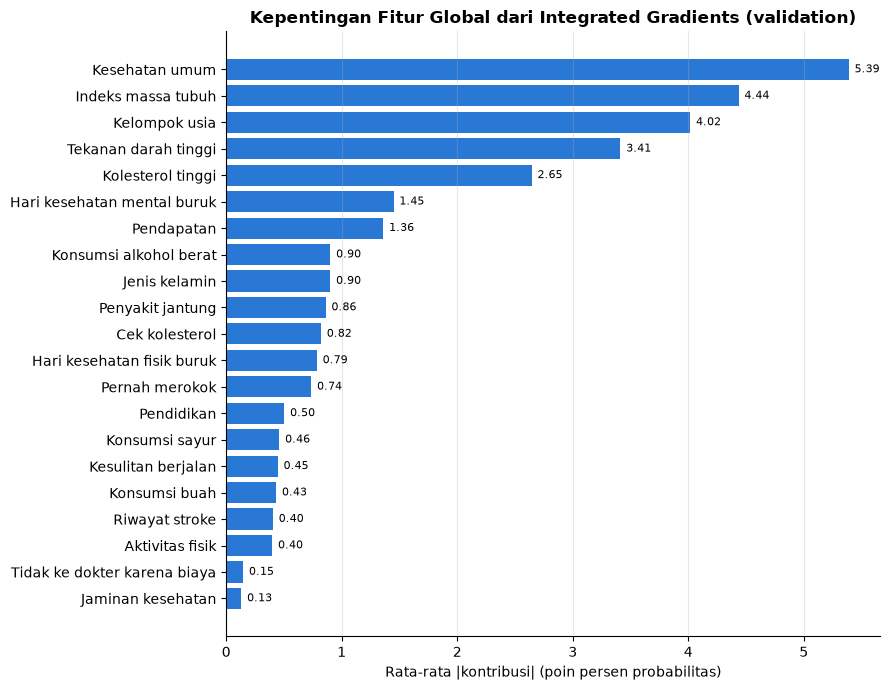

In [7]:
global_imp = pd.DataFrame({
    "nama": [config.FEATURE_INFO[c]["nama"] for c in config.FEATURE_COLS],
    "rata-rata |IG|": np.abs(attr_val).mean(axis=0),
    "rata-rata IG": attr_val.mean(axis=0),
}, index=config.FEATURE_COLS)
train_raw = data["X_train_raw"].assign(target=data["y_train"])
global_imp["spearman dengan label (train)"] = [spearmanr(train_raw[c], train_raw["target"])[0] for c in config.FEATURE_COLS]
global_imp["peringkat IG"] = global_imp["rata-rata |IG|"].rank(ascending=False).astype(int)
global_imp["peringkat |spearman|"] = global_imp["spearman dengan label (train)"].abs().rank(ascending=False).astype(int)
global_imp = global_imp.sort_values("rata-rata |IG|", ascending=False)
global_imp.to_csv(config.RESULTS_DIR / "06_importance_global.csv")
display(global_imp.round(4))

rho = spearmanr(global_imp["rata-rata |IG|"], global_imp["spearman dengan label (train)"].abs())[0]
print(f"Korelasi peringkat IG dengan peringkat |spearman| EDA: {rho:.3f}")

fig, ax = plt.subplots(figsize=(9, 7))
urut = global_imp.sort_values("rata-rata |IG|")
ax.barh(urut["nama"], urut["rata-rata |IG|"] * 100, color=WARNA_UTAMA)
for i, v in enumerate(urut["rata-rata |IG|"] * 100):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Rata-rata |kontribusi| (poin persen probabilitas)")
ax.set_title("Kepentingan Fitur Global dari Integrated Gradients (validation)", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save_fig(fig, "fu2_01_importance_global")
plt.show()

**Interpretasi:** Lima fitur yang paling memengaruhi prediksi adalah **kesehatan umum** (rata-rata 5,39 poin persen), **BMI** (4,44), **usia** (4,02), **tekanan darah tinggi** (3,41), dan **kolesterol tinggi** (2,65). Kelimanya adalah faktor risiko diabetes yang sudah dikenal luas. Usia, obesitas, dan riwayat hipertensi juga termasuk faktor yang dipakai dalam skor skrining diabetes dari Bang dkk. (2009), bersama riwayat keluarga, jenis kelamin, dan aktivitas fisik. Jadi model mengambil keputusan terutama dari faktor yang masuk akal secara medis.

Korelasi peringkat dengan korelasi Spearman di EDA adalah 0,573, cukup searah tetapi tidak identik. Perbedaannya justru informatif:

- `MentHlth` (peringkat 6 di IG, 21 di EDA), `HvyAlcoholConsump` (8 berbanding 14), dan `Sex` (9 berbanding 17) lebih dipakai model daripada yang terlihat dari korelasi langsungnya. Ini tanda model memanfaatkan efek kondisional, yang dibahas di Bagian 6.1.
- `DiffWalk` (16 di IG, 4 di EDA), `PhysActivity` (19 berbanding 10), dan `Stroke` (18 berbanding 11) lebih rendah di IG. Informasi fitur-fitur ini banyak tumpang tindih dengan fitur lain, terutama `GenHlth` (korelasi `DiffWalk` dengan `GenHlth` 0,42 di EDA), sehingga model lebih banyak "menitipkan" sinyal tersebut ke fitur yang lebih kuat.

Rata-rata kontribusi bertanda semuanya kecil, karena kontribusi positif dan negatif di seluruh populasi saling meniadakan. Yang lebih bermakna adalah besar kontribusinya.

## **6. Arah Pengaruh Fitur**

Grafik di bawah memperlihatkan hubungan antara nilai asli fitur dan kontribusinya untuk empat fitur terpenting. Setiap titik adalah satu responden. Titik di atas garis nol berarti fitur tersebut menaikkan probabilitas diabetes dibanding responden rata-rata. Sedikit *jitter* horizontal ditambahkan supaya titik pada nilai diskrit tidak menumpuk.

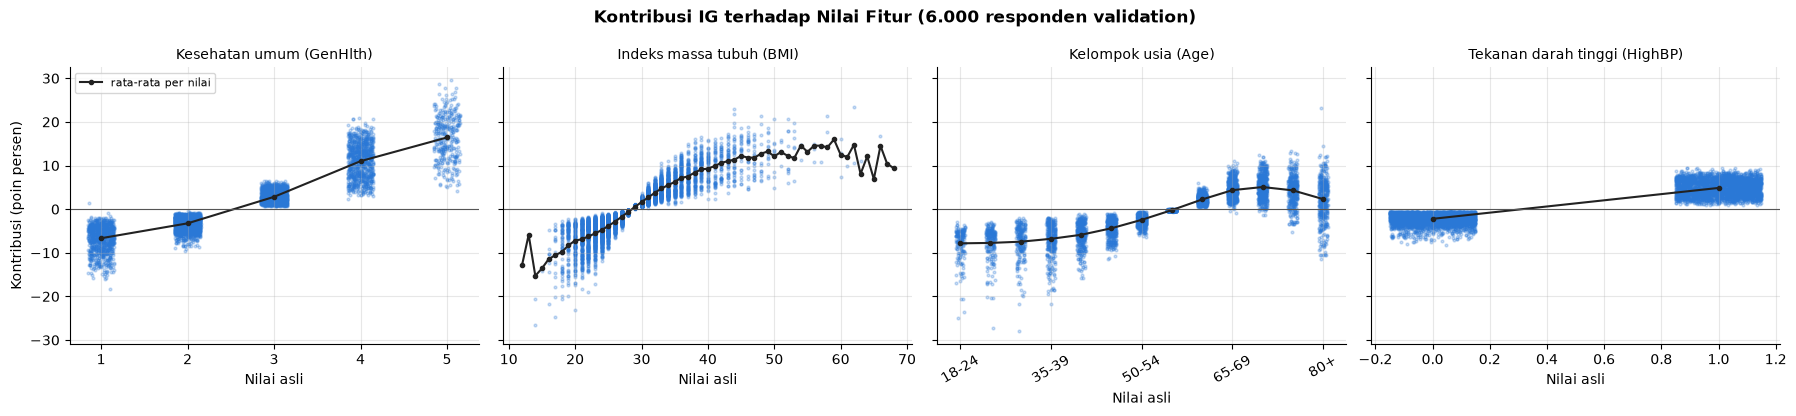

In [8]:
top4 = list(global_imp.index[:4])
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
idx_plot = rng.choice(len(X_val_raw), size=min(6000, len(X_val_raw)), replace=False)
for ax, col in zip(axes, top4):
    k = config.FEATURE_COLS.index(col)
    nilai = X_val_raw[col].to_numpy()[idx_plot].astype(float)
    jitter = rng.uniform(-0.15, 0.15, size=len(nilai)) if X_val_raw[col].nunique() <= 13 else 0
    ax.scatter(nilai + jitter, attr_val[idx_plot, k] * 100, s=4, alpha=0.25, color=WARNA_UTAMA)
    rata = pd.Series(attr_val[:, k] * 100).groupby(X_val_raw[col].to_numpy()).mean()
    ax.plot(rata.index, rata.values, color="#222222", lw=1.5, marker="o", ms=3, label="rata-rata per nilai")
    ax.axhline(0, color="#555555", lw=0.8)
    ax.set_title(f"{config.FEATURE_INFO[col]['nama']} ({col})", fontsize=10)
    ax.set_xlabel("Nilai asli")
    if col == "Age":
        ax.set_xticks([1, 4, 7, 10, 13], [config.AGE_LABELS[i] for i in [1, 4, 7, 10, 13]], rotation=30)
axes[0].set_ylabel("Kontribusi (poin persen)")
axes[0].legend(fontsize=8)
fig.suptitle("Kontribusi IG terhadap Nilai Fitur (6.000 responden validation)", fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "fu2_02_arah_pengaruh")
plt.show()

**Interpretasi:** Arah pengaruh keempat fitur teratas sesuai dengan pengetahuan medis dan temuan EDA:

- **Kesehatan umum** naik secara monoton, dari sekitar -7 poin untuk "Istimewa" sampai sekitar +16 poin untuk "Buruk".
- **BMI** naik dari sekitar -15 poin pada BMI di bawah 20 menjadi sekitar +12 sampai +15 poin pada BMI 45 sampai 60. Di atas BMI 60 garisnya naik-turun karena jumlah responden di rentang itu sangat sedikit, jadi bagian ini tidak bisa dibaca terlalu jauh.
- **Usia** naik dari sekitar -8 poin pada 18 sampai 24 tahun hingga sekitar +5 poin di 70 sampai 74 tahun, lalu turun menjadi sekitar +2 poin di 80 tahun ke atas. Pola ini sama dengan prevalensi di EDA yang memuncak di 70 sampai 74 tahun.
- **Tekanan darah tinggi** "Ya" menambah sekitar +5 poin, sedangkan "Tidak" mengurangi sekitar 2 poin.

Sebaran titik pada usia tua terlihat cukup lebar. Responden dengan usia yang sama bisa mendapat kontribusi berbeda, dan ini dibahas di bagian berikutnya.

### **6.1 Interaksi dan Pola Kondisional**

IG menjelaskan model nonlinear, sehingga kontribusi satu fitur bisa bergantung pada nilai fitur lain. Dua pola yang terlihat di studi kasus diperiksa secara khusus di sini:
1. **Usia dan penyakit penyerta.** Kontribusi usia pada responden 70 tahun ke atas dikelompokkan berdasarkan jumlah penyakit penyerta, yaitu tekanan darah tinggi, kolesterol tinggi, penyakit jantung, kesulitan berjalan, dan stroke.
2. **Kesehatan mental pada tingkat kesehatan umum yang sama.** Kontribusi `MentHlth` dibandingkan antara responden dengan 0 hari dan 14 hari atau lebih kondisi mental buruk, pada setiap nilai `GenHlth`. Hasilnya dicek dengan tingkat diabetes sebenarnya di data train.

In [9]:
ia, im = config.FEATURE_COLS.index("Age"), config.FEATURE_COLS.index("MentHlth")
komorbid = X_val_raw[["HighBP", "HighChol", "HeartDiseaseorAttack", "DiffWalk", "Stroke"]].sum(axis=1).clip(upper=3)
usia_tua = X_val_raw["Age"] >= 11
tabel_usia = pd.DataFrame({
    "jumlah responden": usia_tua.groupby(komorbid).sum(),
    "rata-rata kontribusi Age (poin persen)": pd.Series(attr_val[:, ia] * 100)[usia_tua.to_numpy()].groupby(komorbid[usia_tua]).mean(),
}).rename(index={3: "3 atau lebih"})
tabel_usia.index.name = "jumlah penyakit penyerta (usia 70+)"
display(tabel_usia.round(2))
print(f"Responden usia 70+ dengan kontribusi Age negatif: {(attr_val[usia_tua.to_numpy(), ia] < 0).mean():.1%}")

train_raw2 = data["X_train_raw"].assign(target=data["y_train"])
baris = []
for g in range(1, 6):
    m0 = ((X_val_raw["MentHlth"] == 0) & (X_val_raw["GenHlth"] == g)).to_numpy()
    m14 = ((X_val_raw["MentHlth"] >= 14) & (X_val_raw["GenHlth"] == g)).to_numpy()
    t = train_raw2[train_raw2["GenHlth"] == g]
    baris.append({"GenHlth": f"{g} = {config.GENHLTH_LABELS[g]}",
                  "kontribusi MentHlth=0 (pp)": attr_val[m0, im].mean() * 100,
                  "kontribusi MentHlth>=14 (pp)": attr_val[m14, im].mean() * 100,
                  "% diabetes train, MentHlth=0": t.loc[t["MentHlth"] == 0, "target"].mean() * 100,
                  "% diabetes train, MentHlth>=14": t.loc[t["MentHlth"] >= 14, "target"].mean() * 100})
tabel_mental = pd.DataFrame(baris).set_index("GenHlth").astype(float)
tabel_mental.to_csv(config.RESULTS_DIR / "06_pola_kondisional_mental.csv")
display(tabel_mental.round(2))

,jumlah responden,rata-rata kontribusi Age (poin persen)
jumlah penyakit penyerta (usia 70+),,
0,1183,6.09
1,2293,5.15
2,2516,3.76
3 atau lebih,2137,1.92


Responden usia 70+ dengan kontribusi Age negatif: 12.3%


,kontribusi MentHlth=0 (pp),kontribusi MentHlth>=14 (pp),"% diabetes train, MentHlth=0","% diabetes train, MentHlth>=14"
GenHlth,,,,
1 = Istimewa,1.58,-0.85,3.65,3.53
2 = Sangat baik,1.73,-0.94,9.31,5.85
3 = Baik,1.64,-0.90,19.69,14.99
4 = Cukup,1.39,-1.32,32.85,28.05
5 = Buruk,1.04,-1.76,38.26,37.29


**Interpretasi:** Kedua pemeriksaan menunjukkan bahwa model menangkap **interaksi** antarfitur, bukan sekadar menjumlahkan efek tiap fitur.

**Usia dan penyakit penyerta.** Pada responden 70 tahun ke atas, kontribusi usia rata-rata **+6,09 poin** jika tanpa penyakit penyerta dan terus mengecil hingga **+1,92 poin** jika ada 3 penyakit penyerta atau lebih. Sebanyak 12,3% responden usia 70+ bahkan mendapat kontribusi usia negatif. Ketika risiko sudah dijelaskan oleh tekanan darah tinggi, penyakit jantung, dan kesulitan berjalan, usia tidak banyak menambah informasi lagi.

**Kesehatan mental pada tingkat kesehatan umum yang sama.** Pada kelima tingkat `GenHlth`, model memberi kontribusi positif (+1,04 sampai +1,73 poin) untuk 0 hari kondisi mental buruk dan negatif (-0,85 sampai -1,76 poin) untuk 14 hari atau lebih. Pola ini **didukung data**. Contohnya, pada kelompok kesehatan umum "Cukup", tingkat diabetes 32,85% untuk responden tanpa hari mental buruk, dibanding 28,05% untuk responden dengan 14 hari atau lebih. Arahnya berlawanan dengan korelasi langsung di EDA. Penjelasan yang paling masuk akal: kalau seseorang menilai kesehatannya buruk tanpa ada keluhan mental, penyebabnya lebih mungkin penyakit fisik kronis seperti diabetes.

Pola kedua ini **bukan hubungan sebab akibat**. Kesehatan mental yang baik tidak menyebabkan diabetes. IG hanya menunjukkan pola yang dipakai model. Konsekuensinya untuk aplikasi, penjelasan harus disampaikan sebagai "faktor yang memengaruhi perhitungan model", bukan sebagai saran perubahan perilaku, terutama untuk fitur seperti kesehatan mental, pendapatan, dan pendidikan.

## **7. Deletion Test: Apakah Penjelasan IG Setia pada Model**

Penjelasan yang baik harus menunjuk fitur yang benar-benar menggerakkan prediksi. Cara mengujinya adalah *deletion test* (Petsiuk dkk., 2018). Fitur dinetralkan satu per satu, yaitu diganti dengan nilai baseline, lalu perubahan probabilitasnya diamati. Kalau urutan dari IG memang tepat, probabilitas akan turun paling cepat.

Pengujian dilakukan pada semua responden validation yang diprediksi **berisiko** (probabilitas >= threshold), karena untuk kelompok inilah aplikasi menjelaskan "mengapa berisiko". Tiga urutan dibandingkan:
1. **IG per responden:** fitur dengan kontribusi terbesar dinetralkan lebih dulu, dan urutannya berbeda untuk setiap orang.
2. **Global:** urutan yang sama untuk semua orang, berdasarkan rata-rata kontribusi di kelompok berisiko.
3. **Acak:** rata-rata dari 5 urutan acak.

Semakin kecil luas di bawah kurva (rata-rata probabilitas selama penghapusan), semakin baik urutannya.

Responden diprediksi berisiko: 14,019 dari 34,332


,luas di bawah kurva,prob. awal,prob. setelah 1 fitur,prob. setelah 3 fitur,% turun di bawah threshold (3 fitur)
IG per responden,0.0864,0.2807,0.1973,0.1169,64.0631
Global,0.1326,0.2807,0.2362,0.1823,21.1998
Acak,0.1973,0.2807,0.2737,0.2595,5.0931


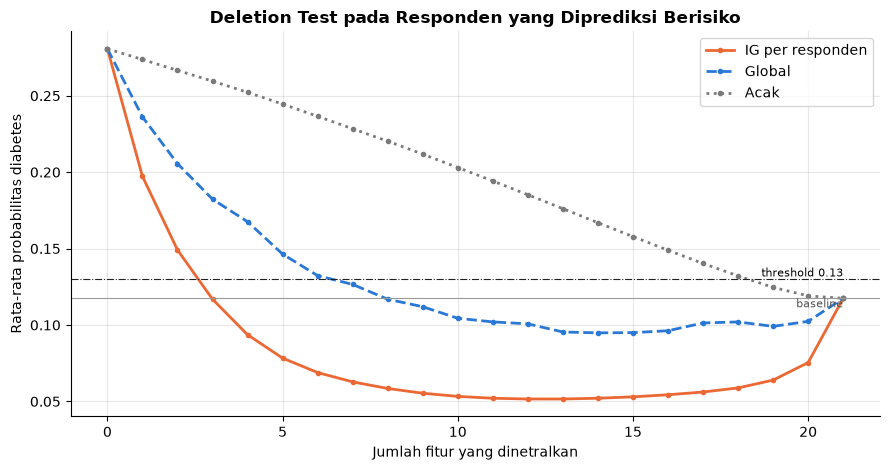

In [10]:
def kurva_deletion(X, urutan):
    """urutan: (n, d) indeks fitur. Mengembalikan probabilitas (n, d + 1) setelah k fitur dinetralkan."""
    Xc = X.copy()
    n, d = X.shape
    hasil = np.zeros((n, d + 1), dtype=np.float32)
    hasil[:, 0] = inf.predict_proba(model, Xc)
    baris = np.arange(n)
    for k in range(d):
        kol = urutan[:, k]
        Xc[baris, kol] = baseline[kol]
        hasil[:, k + 1] = inf.predict_proba(model, Xc)
    return hasil

berisiko = prob_val >= THRESHOLD
X_r, A_r = X_val[berisiko], attr_val[berisiko]
n_r, d = X_r.shape
print(f"Responden diprediksi berisiko: {n_r:,} dari {len(X_val):,}")

urut_ig = np.argsort(-A_r, axis=1)
urut_global = np.tile(np.argsort(-A_r.mean(axis=0)), (n_r, 1))
kurva = {"IG per responden": kurva_deletion(X_r, urut_ig), "Global": kurva_deletion(X_r, urut_global)}
acak = [kurva_deletion(X_r, np.array([rng.permutation(d) for _ in range(n_r)])) for _ in range(5)]
kurva["Acak"] = np.mean(acak, axis=0)

ringkas_del = pd.DataFrame({
    nama: {"luas di bawah kurva": k_.mean(axis=0).mean(),
           "prob. awal": k_[:, 0].mean(),
           "prob. setelah 1 fitur": k_[:, 1].mean(),
           "prob. setelah 3 fitur": k_[:, 3].mean(),
           "% turun di bawah threshold (3 fitur)": (k_[:, 3] < THRESHOLD).mean() * 100}
    for nama, k_ in kurva.items()
}).T
ringkas_del.to_csv(config.RESULTS_DIR / "06_deletion_test.csv")
display(ringkas_del.round(4))

fig, ax = plt.subplots(figsize=(9, 4.8))
gaya = {"IG per responden": (WARNA_NAIK, "-"), "Global": (WARNA_TURUN, "--"), "Acak": ("#7a7a7a", ":")}
for nama, k_ in kurva.items():
    warna, ls = gaya[nama]
    ax.plot(range(d + 1), k_.mean(axis=0), color=warna, ls=ls, lw=2, marker="o", ms=3, label=nama)
ax.axhline(THRESHOLD, color="#222222", lw=0.8, ls="-.")
ax.text(d, THRESHOLD, f" threshold {THRESHOLD}", va="bottom", ha="right", fontsize=8)
ax.axhline(baseline_prob, color="#9A9A9A", lw=0.8)
ax.text(d, baseline_prob, " baseline", va="top", ha="right", fontsize=8, color="#555555")
ax.set_xlabel("Jumlah fitur yang dinetralkan")
ax.set_ylabel("Rata-rata probabilitas diabetes")
ax.set_title("Deletion Test pada Responden yang Diprediksi Berisiko", fontweight="bold")
ax.legend()
fig.tight_layout()
viz.save_fig(fig, "fu2_03_deletion_test")
plt.show()

**Interpretasi:** Deletion test diterapkan pada 14.019 responden yang diprediksi berisiko, dengan rata-rata probabilitas awal 0,2807. Hasilnya sangat jelas membedakan ketiga urutan:

| Urutan | Setelah 1 fitur | Setelah 3 fitur | Turun di bawah threshold (3 fitur) | Luas di bawah kurva |
|---|---|---|---|---|
| IG per responden | 0,1973 | 0,1169 | 64,1% | 0,0864 |
| Global | 0,2362 | 0,1823 | 21,2% | 0,1326 |
| Acak | 0,2737 | 0,2595 | 5,1% | 0,1973 |

Menetralkan hanya **3 fitur yang ditunjuk IG** sudah cukup membuat 64,1% responden berisiko turun ke bawah threshold. Dengan urutan acak, angkanya hanya 5,1%. Ini bukti bahwa fitur yang ditunjuk IG memang yang paling menggerakkan prediksi.

Yang lebih penting, urutan **IG per responden jauh lebih baik daripada urutan global** (64,1% berbanding 21,2%). Artinya penjelasan individual memberi informasi yang tidak bisa didapat hanya dari daftar "fitur terpenting secara umum". Setiap orang punya faktor pendorong risiko yang berbeda, dan IG menangkap perbedaan itu.

Ketiga kurva berakhir di probabilitas baseline (0,1175) ketika semua fitur sudah dinetralkan. Kurva IG sempat turun di bawah baseline lalu naik kembali di ujung, karena fitur yang dinetralkan terakhir adalah fitur dengan kontribusi negatif. Pola ini konsisten dengan sifat completeness.